## Classification

To run this script, you need the following files found in the /data directory:
- "final_labels_SG1.xlsx"
- "final_labels_SG2.xlsx"

## Imports and set-up

In [ ]:
# Resolve paths relative to the repository root so this notebook runs from the repo
# root, from notebooks/, or on Colab after cloning the repo:
#   !git clone https://github.com/yasmeenhany/media-bias-detection.git
#   %cd media-bias-detection
import os
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
os.chdir(REPO_ROOT)
print("Working directory:", REPO_ROOT)

In [19]:
!pip install transformers
!pip install sentencepiece

In [20]:
!nvidia-smi

Mon Dec  2 21:02:22 2024       
+---------------------------------------------------------------------------------------+
| NVIDIA-SMI 535.104.05             Driver Version: 535.104.05   CUDA Version: 12.2     |
|-----------------------------------------+----------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id        Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |         Memory-Usage | GPU-Util  Compute M. |
|                                         |                      |               MIG M. |
|=========================================+======================+======================|
|   0  NVIDIA L4                      Off | 00000000:00:03.0 Off |                    0 |
| N/A   74C    P0              33W /  72W |  16677MiB / 23034MiB |      0%      Default |
|                                         |                      |                  N/A |
+-----------------------------------------+----------------------+--

In [21]:
import sys
import os
import time
import re
import random
from typing import Dict, List, Optional, Union
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import tensorflow as tf
from transformers import BertTokenizer, BertConfig, TFBertForSequenceClassification
from transformers import DistilBertTokenizer, TFDistilBertForSequenceClassification
from transformers import RobertaTokenizer, TFRobertaForSequenceClassification
from transformers import ElectraTokenizer, TFElectraForSequenceClassification
from transformers import XLNetTokenizer, TFXLNetForSequenceClassification
from transformers import LongformerTokenizer, TFLongformerForSequenceClassification
from transformers import T5Tokenizer, TFT5ForConditionalGeneration, T5ForConditionalGeneration
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
from transformers import AdamW

In [22]:
# set seed, TF uses python ramdom and numpy library, so these must also be fixed
tf.random.set_seed(0)
random.seed(0)
np.random.seed(0)
os.environ['PYTHONHASHSEED']=str(0)
os.environ['TF_DETERMINISTIC_OPS'] = '0'

In [23]:
# see if hardware accelerator available
tf.config.experimental.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'),
 PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [24]:
tf.test.gpu_device_name()

'/device:GPU:0'

If GPUs are available, tensorflow will give priority to it automatically and computations will be performed on the GPU as default. That behavior can be changed by assigning a task explicitly to a device. Example:

```
with tf.device('/CPU:0'):
```



## Preprocessing

In [29]:
PATH_sg1 = "data/final_labels_SG1.xlsx"
PATH_sg2 = "data/final_labels_SG2.xlsx"
df_sg1 = pd.read_excel(PATH_sg1)
df_sg2 = pd.read_excel(PATH_sg2)
df_sg1.rename(columns={'text': 'sentence', 'label_bias': 'Label_bias'}, inplace=True)
df_sg2.rename(columns={'text': 'sentence', 'label_bias': 'Label_bias'}, inplace=True)
df_sg1.head()

,sentence,news_link,outlet,topic,type,Label_bias,label_opinion,biased_words
0,The Republican president assumed he was helpin...,http://www.msnbc.com/rachel-maddow-show/auto-i...,msnbc,environment,left,Biased,Expresses writer’s opinion,[]
1,Though the indictment of a woman for her own p...,https://eu.usatoday.com/story/news/nation/2019...,usa-today,abortion,center,Non-biased,Somewhat factual but also opinionated,[]
2,Ingraham began the exchange by noting American...,https://www.breitbart.com/economy/2020/01/12/d...,breitbart,immigration,right,No agreement,No agreement,['flood']
3,The tragedy of America’s 18 years in Afghanist...,http://feedproxy.google.com/~r/breitbart/~3/ER...,breitbart,international-politics-and-world-news,right,Biased,Somewhat factual but also opinionated,"['tragedy', 'stubborn']"
4,The justices threw out a challenge from gun ri...,https://www.huffpost.com/entry/supreme-court-g...,msnbc,gun-control,left,Non-biased,Entirely factual,[]


In [30]:
# binarize classification problem
df_sg1 = df_sg1[df_sg1['Label_bias']!='No agreement']
df_sg1 = df_sg1[df_sg1['Label_bias'].isna()==False]
df_sg1.replace(to_replace='Biased', value=1, inplace=True)
df_sg1.replace(to_replace='Non-biased', value=0, inplace=True)

df_sg2 = df_sg2[df_sg2['Label_bias']!='No agreement']
df_sg2.replace(to_replace='Biased', value=1, inplace=True)
df_sg2.replace(to_replace='Non-biased', value=0, inplace=True)

<ipython-input-30-3610be668419>:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_sg1.replace(to_replace='Non-biased', value=0, inplace=True)
<ipython-input-30-3610be668419>:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sg2.replace(to_replace='Biased', value=1, inplace=True)
<ipython-input-30-3610be668419>:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcas

In [31]:
# Stratified k-Fold instance
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

The rest of the preprocessing needs to be performed inside the folds as a) encoder layers shouldn't be allowed to see whole data to construct the lookups and b) indexing with skfold is not possible when data is in tensorflow format.

In [32]:
# helper functions called in skfold loop

def pd_to_tf(df):
    """convert a pandas dataframe into a tensorflow dataset"""
    target = df.pop('Label_bias')
    sentence = df.pop('sentence')
    return tf.data.Dataset.from_tensor_slices((sentence.values, target.values))

def plot_graphs(history, metric):
  plt.plot(history.history[metric])
  plt.plot(history.history['val_'+metric], '')
  plt.xlabel("Epochs")
  plt.ylabel(metric)
  plt.legend([metric, 'val_'+metric])
  plt.show()

def tokenize(df):
    """convert a pandas dataframe into a tensorflow dataset and run hugging face's tokenizer on data"""
    target = df.pop('Label_bias')
    sentence = df.pop('sentence')

    train_encodings = tokenizer(
                        sentence.tolist(),
                        add_special_tokens = True, # add [CLS], [SEP]
                        truncation = True, # cut off at max length of the text that can go to BERT
                        padding = True, # add [PAD] tokens
                        return_attention_mask = True, # add attention mask to not focus on pad tokens
              )

    dataset = tf.data.Dataset.from_tensor_slices(
        (dict(train_encodings),
         target.tolist()))
    return dataset

## Attention-based models


###T5 (encoder + decoder)

In [ ]:
# import sys
# def tokenize_data(data):
#   inputs = tokenizer(data["sentence"].apply(
#       lambda x:
#       """Classify the news sentence after the colon as either '<s> Biased </s>' or '<s> Non-biased </s>'. Don't output any other word.:"""  + x).tolist(),
#                      max_length=256, padding="max_length", truncation=True, return_tensors="tf")
#   targets = tokenizer(data["Label_bias"].replace({0: "<s> Biased </s>", 1: "<s> Non-biased </s>"}).tolist(), padding="longest", return_tensors="tf")
#   # print("tokenizer ip", data["Label_bias"].replace({0: "Non-biased", 1: "Biased"}).tolist())
#   # print("target input ids", targets["input_ids"][3])
#   # print("target input ids", targets["input_ids"][4])
#   # tokens = tokenizer(["Non-biased", "Biased"], truncation=True, padding="longest", return_tensors="tf")
#   # print("tokenizer", tokens["input_ids"])
#   # print("Input IDs shape:", inputs["input_ids"].shape)
#   # decoded_text = tokenizer.decode(targets["input_ids"][3], skip_special_tokens=True)
#   # print("Decoded text:", decoded_text)
#   # print(targets["input_ids"][:, 1:])
#   # decoded_text = tokenizer.decode(targets["input_ids"][0, 1:], skip_special_tokens=True)

#   # print("Decoded text:", decoded_text)
#   # decoded_text = tokenizer.decode(inputs["input_ids"][1], skip_special_tokens=True)
#   # print("original input:", data["sentence"][6])
#   # print("Decoded input:", decoded_text)

#   # sys.exit()

#   # Prepare dataset with decoder input IDs
#   dataset = tf.data.Dataset.from_tensor_slices(({
#       "input_ids": inputs["input_ids"],
#       "attention_mask": inputs["attention_mask"],
#       "decoder_input_ids": targets["input_ids"][:, :-4],  # Exclude the last token for decoder input
#   }, targets["input_ids"][:, 4:]))  # Exclude the first token for labels
#   return dataset

# def save_misclassifications(data, ground_truths, predictions):
#   # Create a DataFrame with predictions, ground truths, and input data
#   df = pd.DataFrame({
#       "Input": data,
#       "Ground Truth": ground_truths,
#       "Prediction": predictions
#   })

#   # Filter misclassifications
#   misclassified_df = df[df["Ground Truth"] != df["Prediction"]]

#   # Save misclassifications to a CSV file
#   misclassified_df.to_csv("misclassified_examples.csv", index=False)
#   return misclassified_df

# def run_model_5fold(df_train, model_name, freeze_encoder=True, pretrained=False, plot=False):
#     """
#     Implements 5-fold cross-validation with transformer models.
#     """
#     Y = df_train['Label_bias']
#     X = df_train['sentence']

#     BUFFER_SIZE = 10000
#     BATCH_SIZE = 64
#     k = 1
#     epochs = 5

#     val_loss = []
#     val_acc = []
#     val_prec = []
#     val_rec = []
#     val_f1 = []
#     val_f1_micro = []
#     val_f1_wmacro = []
#     val_f1_per_class = []

#     skfold = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

#     for train_index, val_index in skfold.split(X, Y):
#         print('### Start fold {}'.format(k))

#         # Split into train and validation sets
#         train_dataset = df_train.iloc[train_index]
#         val_dataset = df_train.iloc[val_index]
#         val_dataset_og = val_dataset
#         # Prepare data for transformer
#         if model_name == "t5":
#           train_dataset = tokenize_data(train_dataset)
#           val_dataset = tokenize_data(val_dataset)
#         else:
#             train_dataset = tokenize(train_dataset)
#             val_dataset = tokenize(val_dataset)

#         # Mini-batch it
#         train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.experimental.AUTOTUNE)
#         val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.experimental.AUTOTUNE)

#         # Extract true labels
#         y = []
#         sentences = []
#         for x, label in val_dataset.unbatch():
#             y.append(label.numpy())
#         if model_name == "t5":
#           decoded_y = [tokenizer.decode(batch, skip_special_tokens=True) for batch in y]
#           print(f"decoded_y: {decoded_y}")
#           # Map decoded labels to binary
#           y = [0 if label == "Non-biased" else 1 for label in decoded_y]


#         # Create new model
#         if model_name == 'bert':
#             model = TFBertForSequenceClassification.from_pretrained("bert-base-uncased")
#         elif model_name == 'distilbert':
#             model = TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased')
#         elif model_name == 'roberta':
#             model = TFRobertaForSequenceClassification.from_pretrained('roberta-base')
#         elif model_name == 'electra':
#             model = TFElectraForSequenceClassification.from_pretrained('google/electra-small-discriminator')
#         elif model_name == 'xlnet':
#             model = TFXLNetForSequenceClassification.from_pretrained('xlnet-base-cased')
#         elif model_name == 't5':
#             model = TFT5ForConditionalGeneration.from_pretrained("google/flan-t5-small")

#         if freeze_encoder and model_name != "t5":
#             for w in model.get_layer(index=0).weights:
#                 w._trainable = False

#         # Compile the model
#         optimizer = tf.keras.optimizers.Adam(learning_rate=1e-5)
#         model.compile(optimizer=optimizer, loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True))

#         # Add EarlyStopping callback
#         callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True)

#         if model_name == "t5":
#           history = model.fit(train_dataset, epochs=epochs, validation_data=val_dataset, callbacks=[callback])
#         else:
#          history = model.fit(train_dataset, epochs=epochs, validation_data=val_dataset, callbacks=[callback])


#         if plot:
#           plot_graphs(history,'loss')

#         # Evaluate the model
#         loss = model.evaluate(val_dataset)

#         # Generate predictions
#         if model_name == 'xlnet':
#             yhats = []
#             for row in df_train.iloc[val_index]['sentence']:
#                 input_ids = tokenizer(row, return_tensors="tf")
#                 output = model(input_ids)
#                 logits = output.logits.numpy()[0]
#                 decision = logits.argmax()
#                 yhats.append(decision)
#         elif model_name == 't5':
#           def predict(dataset):
#             yhats = []
#             all_decoded_outputs = []
#             for batch in dataset:
#                 inputs, _ = batch
#                 outputs = model.generate(inputs["input_ids"], temperature=0.3)
#                 decoded_outputs = [tokenizer.decode(output, skip_special_tokens=True) for output in outputs]
#                 print(decoded_outputs)
#                 all_decoded_outputs.extend(decoded_outputs)
#                 yhats.extend([0 if output == "Non-biased" else 1 for output in decoded_outputs])
#             return all_decoded_outputs, yhats

#           decoded_outputs, yhats = predict(val_dataset)
#           misclassified_df = save_misclassifications(val_dataset_og["sentence"], decoded_y, decoded_outputs )

#         else:
#             logits = model.predict(val_dataset)
#             yhats = []
#             for i in logits[0]:
#                 candidates = i.tolist()
#                 decision = candidates.index(max(candidates))
#                 yhats.append(decision)



#         print(f"y (true labels after decoding): {y[:5]} (type: {type(y)}, length: {len(y)})")
#         print(f"yhats (predicted labels): {yhats[:5]} (type: {type(yhats)}, length: {len(yhats)})")

#         # Calculate metrics
#         val_loss.append(loss)
#         val_acc.append(accuracy_score(y, yhats))
#         val_prec.append(precision_score(y, yhats))
#         val_rec.append(recall_score(y, yhats))
#         val_f1.append(f1_score(y, yhats))
#         val_f1_micro.append(f1_score(y, yhats, average='micro'))
#         val_f1_wmacro.append(f1_score(y, yhats, average='weighted'))
#         val_f1_per_class.append(f1_score(y, yhats, average=None))

#         tf.keras.backend.clear_session()
#         k += 1

#     return val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro, val_f1_per_class


### T5 (encoder only + classification head)

In [13]:
import sys
def tokenize_data(data):
    # Tokenize input sentences with T5 prompt
    inputs = tokenizer(data["sentence"].apply(
        lambda x: "" + """Classify the news sentence after the colon as either 1 for Biased or 0 for Non-biased:""" + x).tolist(),
        max_length=256, padding="max_length", truncation=True, return_tensors="tf")

    # Map the labels to the desired format (one-hot encoding)
    label_map = {0: [1, 0], 1: [0, 1]}  # 0 -> Non-biased -> [1, 0], 1 -> Biased -> [0, 1]
    one_hot_labels = data["Label_bias"].map(label_map).tolist()
    targets = tf.convert_to_tensor(one_hot_labels, dtype=tf.int32)  # Convert to tensor
    # Create TensorFlow dataset
    dataset = tf.data.Dataset.from_tensor_slices((
        {"input_ids": inputs["input_ids"], "attention_mask": inputs["attention_mask"]},
        targets
    ))

    return dataset

def save_misclassifications(data, ground_truths, predictions):
  # Create a DataFrame with predictions, ground truths, and input data
  df = pd.DataFrame({
      "Input": data,
      "Ground Truth": ground_truths,
      "Prediction": predictions
  })
  # Filter misclassifications
  misclassified_df = df[df["Ground Truth"] != df["Prediction"]]

  # Save misclassifications to a CSV file
  misclassified_df.to_csv("misclassified_examples.csv", index=False)
  return misclassified_df

class T5WithClassificationHead(tf.keras.Model):
    def __init__(self, base_model, num_classes):
        super(T5WithClassificationHead, self).__init__()
        self.base_model = base_model
        self.num_classes = num_classes
        self.classifier = tf.keras.layers.Dense(num_classes, activation="softmax")

    def call(self, input_ids, attention_mask=None):
        encoder_outputs = self.base_model.encoder(input_ids=input_ids, attention_mask=attention_mask)[0]

        pooled_output = tf.reduce_mean(encoder_outputs, axis=1)

        logits = self.classifier(pooled_output)
        return logits

def run_model_5fold(df_train, model_name, freeze_encoder=True, pretrained=False, plot=False):
    """
    Implements 5-fold cross-validation with transformer models.
    """
    Y = df_train['Label_bias']
    X = df_train['sentence']

    BUFFER_SIZE = 10000
    BATCH_SIZE = 16
    k = 1
    epochs = 5

    val_loss = []
    val_acc = []
    val_prec = []
    val_rec = []
    val_f1 = []
    val_f1_micro = []
    val_f1_wmacro = []
    val_f1_per_class = []

    skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    for train_index, val_index in skfold.split(X, Y):
        print('### Start fold {}'.format(k))

        # Split into train and validation sets
        train_dataset = df_train.iloc[train_index]
        val_dataset = df_train.iloc[val_index]
        val_dataset_og = val_dataset
        # Prepare data for transformer
        if model_name == "t5":
          train_dataset = tokenize_data(train_dataset)
          val_dataset = tokenize_data(val_dataset)
        else:
            train_dataset = tokenize(train_dataset)
            val_dataset = tokenize(val_dataset)

        # Mini-batch it
        train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.experimental.AUTOTUNE)
        val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.experimental.AUTOTUNE)

        # Extract true labels
        y = []
        sentences = []
        for x, label in val_dataset.unbatch():
          if model_name == "t5":
            true_label = tf.argmax(label, axis=-1).numpy()  # Assuming labels are one-hot encoded
            y.append(true_label)
          else:
            y.append(label.numpy())
        #   print(batch)
        #   decoded_y = [tokenizer.decode(batch, skip_special_tokens=True) for batch in y]
        #   print(f"decoded_y: {decoded_y}")
        #   # Map decoded labels to binary
        #   y = [0 if label == "Non-biased" else 1 for label in decoded_y]


        # Create new model
        if model_name == 'bert':
            model = TFBertForSequenceClassification.from_pretrained("bert-base-uncased")
        elif model_name == 'distilbert':
            model = TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased')
        elif model_name == 'roberta':
            model = TFRobertaForSequenceClassification.from_pretrained('roberta-base')
        elif model_name == 'electra':
            model = TFElectraForSequenceClassification.from_pretrained('google/electra-small-discriminator')
        elif model_name == 'xlnet':
            model = TFXLNetForSequenceClassification.from_pretrained('xlnet-base-cased')
        elif model_name == 't5':
            model = TFT5ForConditionalGeneration.from_pretrained("google/flan-t5-base")
            model = T5WithClassificationHead(model, 2)

        if freeze_encoder and model_name != "t5":
            for w in model.get_layer(index=0).weights:
                w._trainable = False

        # Compile the model
        optimizer = tf.keras.optimizers.Adam(learning_rate=2e-5)
        model.compile(optimizer=optimizer, loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False))

        # Add EarlyStopping callback
        callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True)

        if model_name == "t5":
          history = model.fit(train_dataset, epochs=epochs, validation_data=val_dataset, callbacks=[callback])
        else:
         history = model.fit(train_dataset, epochs=epochs, validation_data=val_dataset, callbacks=[callback])


        if plot:
          plot_graphs(history,'loss')

        # Evaluate the model
        loss = model.evaluate(val_dataset)

        # Generate predictions
        if model_name == 'xlnet':
            yhats = []
            for row in df_train.iloc[val_index]['sentence']:
                input_ids = tokenizer(row, return_tensors="tf")
                output = model(input_ids)
                logits = output.logits.numpy()[0]
                decision = logits.argmax()
                yhats.append(decision)
        elif model_name == 't5':
          def predict(dataset):
              yhats = []
              all_decoded_outputs = []
              for batch in dataset:
                  inputs, _ = batch  # Inputs are tokenized input ids and attention masks

                  # Get logits from the model instead of using generate
                  logits = model(inputs["input_ids"], attention_mask=inputs["attention_mask"])

                  # Apply argmax to get predicted class index (0 or 1)
                  predictions = tf.argmax(logits, axis=-1).numpy()  # Get the class with the highest logit
                  yhats.extend(predictions)

              return yhats

          yhats = predict(val_dataset)
          misclassified_df = save_misclassifications(val_dataset_og["sentence"], y, yhats)

        else:
            logits = model.predict(val_dataset)
            yhats = []
            for i in logits[0]:
                candidates = i.tolist()
                decision = candidates.index(max(candidates))
                yhats.append(decision)



        print(f"y (true labels after decoding): {y[:5]} (type: {type(y)}, length: {len(y)})")
        print(f"yhats (predicted labels): {yhats[:5]} (type: {type(yhats)}, length: {len(yhats)})")

        # Calculate metrics
        val_loss.append(loss)
        val_acc.append(accuracy_score(y, yhats))
        val_prec.append(precision_score(y, yhats))
        val_rec.append(recall_score(y, yhats))
        val_f1.append(f1_score(y, yhats))
        val_f1_micro.append(f1_score(y, yhats, average='micro'))
        val_f1_wmacro.append(f1_score(y, yhats, average='weighted'))
        val_f1_per_class.append(f1_score(y, yhats, average=None))

        tf.keras.backend.clear_session()
        k += 1

    return val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro, val_f1_per_class


/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


78/78 [==============================] - 60s 379ms/step - loss: 0.6768 - val_loss: 0.6127
Epoch 2/5
78/78 [==============================] - 26s 329ms/step - loss: 0.5905 - val_loss: 0.4755
Epoch 3/5
78/78 [==============================] - 26s 331ms/step - loss: 0.4831 - val_loss: 0.4123
Epoch 4/5
78/78 [==============================] - 26s 331ms/step - loss: 0.4148 - val_loss: 0.3908
Epoch 5/5
78/78 [==============================] - 25s 326ms/step - loss: 0.3644 - val_loss: 0.4722


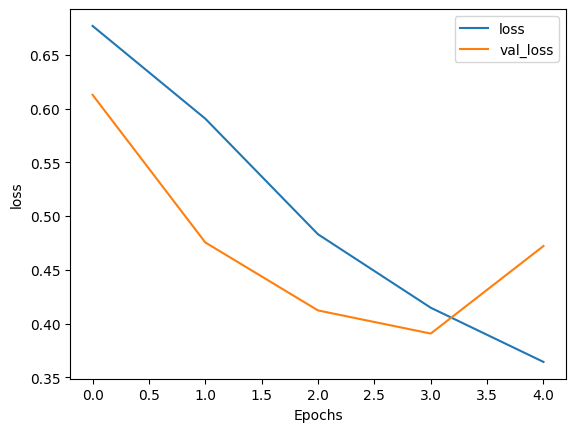

20/20 [==============================] - 2s 89ms/step - loss: 0.3908
y (true labels after decoding): [0, 1, 1, 0, 0] (type: <class 'list'>, length: 310)
yhats (predicted labels): [0, 1, 1, 0, 0] (type: <class 'list'>, length: 310)
### Start fold 2


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


78/78 [==============================] - 53s 383ms/step - loss: 0.6763 - val_loss: 0.6264
Epoch 2/5
78/78 [==============================] - 26s 333ms/step - loss: 0.6060 - val_loss: 0.5467
Epoch 3/5
78/78 [==============================] - 25s 326ms/step - loss: 0.5244 - val_loss: 0.5685


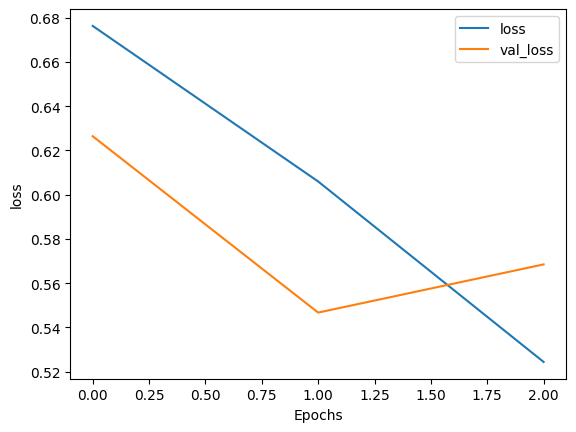

20/20 [==============================] - 2s 90ms/step - loss: 0.5467
y (true labels after decoding): [1, 1, 1, 0, 1] (type: <class 'list'>, length: 309)
yhats (predicted labels): [1, 1, 1, 0, 1] (type: <class 'list'>, length: 309)
### Start fold 3


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


78/78 [==============================] - 54s 384ms/step - loss: 0.6662 - val_loss: 0.6319
Epoch 2/5
78/78 [==============================] - 26s 334ms/step - loss: 0.5645 - val_loss: 0.5648
Epoch 3/5
78/78 [==============================] - 25s 326ms/step - loss: 0.4642 - val_loss: 0.5699


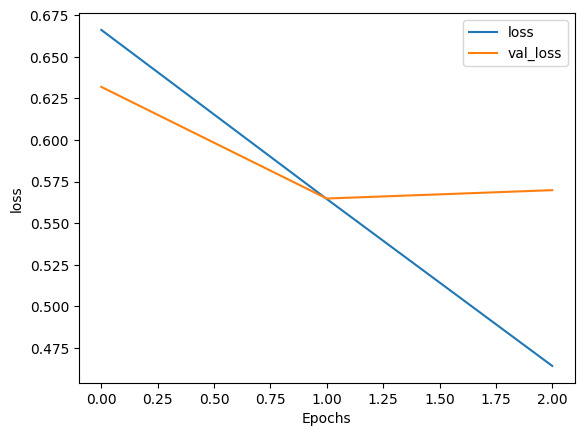

20/20 [==============================] - 2s 90ms/step - loss: 0.5648
y (true labels after decoding): [0, 1, 0, 1, 1] (type: <class 'list'>, length: 309)
yhats (predicted labels): [0, 0, 0, 0, 1] (type: <class 'list'>, length: 309)
### Start fold 4


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


78/78 [==============================] - 54s 384ms/step - loss: 0.6695 - val_loss: 0.6174
Epoch 2/5
78/78 [==============================] - 26s 334ms/step - loss: 0.5691 - val_loss: 0.5275
Epoch 3/5
78/78 [==============================] - 26s 334ms/step - loss: 0.4577 - val_loss: 0.5189
Epoch 4/5
78/78 [==============================] - 25s 325ms/step - loss: 0.3895 - val_loss: 0.5399


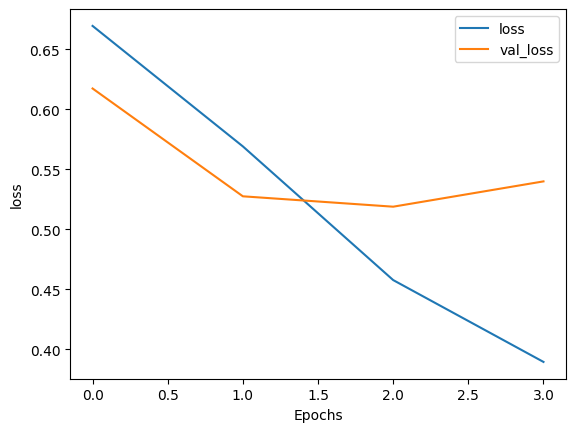

20/20 [==============================] - 2s 89ms/step - loss: 0.5189
y (true labels after decoding): [0, 0, 1, 0, 1] (type: <class 'list'>, length: 309)
yhats (predicted labels): [0, 0, 0, 0, 1] (type: <class 'list'>, length: 309)
### Start fold 5


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


78/78 [==============================] - 55s 386ms/step - loss: 0.6739 - val_loss: 0.5804
Epoch 2/5
78/78 [==============================] - 26s 333ms/step - loss: 0.5800 - val_loss: 0.4378
Epoch 3/5
78/78 [==============================] - 25s 325ms/step - loss: 0.4690 - val_loss: 0.4541


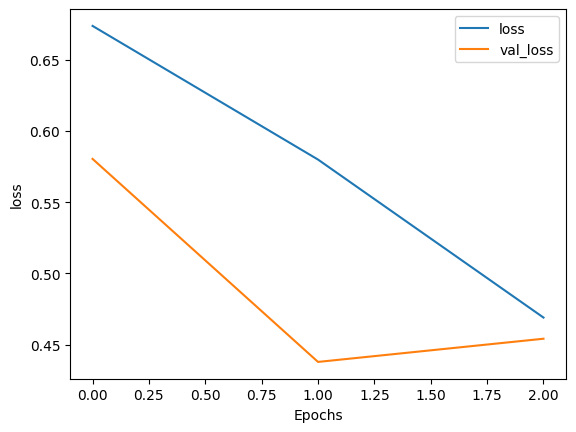

20/20 [==============================] - 2s 90ms/step - loss: 0.4378
y (true labels after decoding): [0, 0, 1, 0, 1] (type: <class 'list'>, length: 309)
yhats (predicted labels): [0, 0, 1, 0, 1] (type: <class 'list'>, length: 309)
5-Fold CV Loss: 0.4917994499206543
5-Fold CV Accuracy: 0.78650589831924
5-Fold CV Precision: 0.7787444596713459
5-Fold CV Recall: 0.7841163310961968
5-Fold CV F1 Score: 0.7805641444208509
5-Fold CV Micro F1 Score: 0.78650589831924
5-Fold CV Weighted Macro F1 Score: 0.7862890418896502
5 fold f1 per class [array([0.85448916, 0.84175084]), array([0.72909699, 0.7460815 ]), array([0.75308642, 0.72789116]), array([0.78864353, 0.77740864]), array([0.83282675, 0.80968858])]


In [14]:
tokenizer = T5Tokenizer.from_pretrained("google/flan-t5-base")
# without distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro, val_f1_per_class = run_model_5fold(df_sg1, model_name='t5',
                                                                                            freeze_encoder=False, pretrained=False, plot=True)

# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))
print("5 fold f1 per class", val_f1_per_class)

In [16]:
misclassifications_df = pd.read_csv("misclassified_examples.csv")
print(misclassifications_df.shape)
print(misclassifications_df[(misclassifications_df["Ground Truth"] == 1) & (misclassifications_df["Prediction"] == 0)].shape)

(55, 3)


(32, 3)

### plots

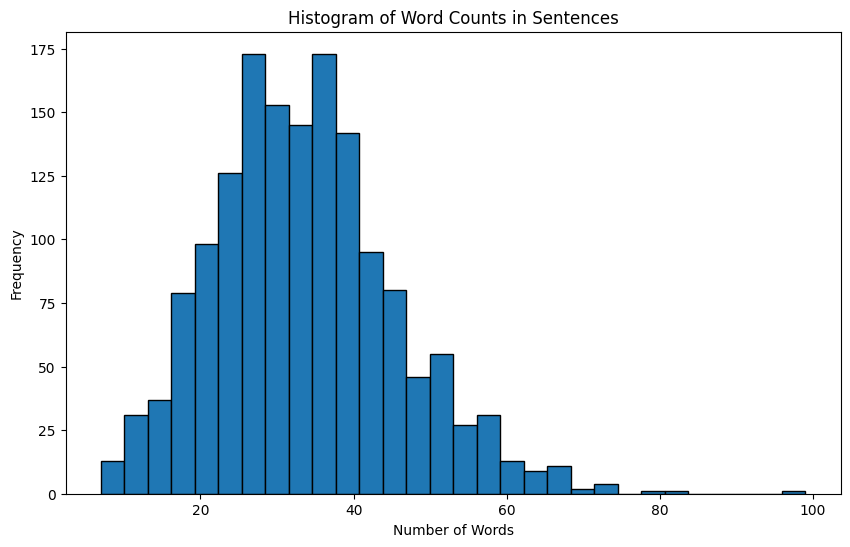

In [66]:
import matplotlib.pyplot as plt


df_sg1['word_count'] = df_sg1['sentence'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
plt.hist(df_sg1['word_count'], bins=30, edgecolor='black')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.title('Histogram of Word Counts in Sentences')
plt.show()

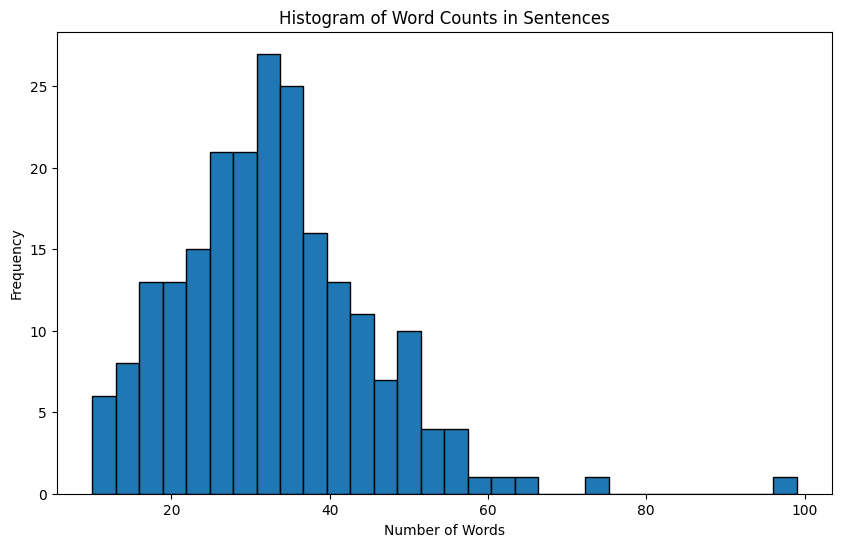

In [68]:
import matplotlib.pyplot as plt


misclassifications_df['word_count'] = misclassifications_df['Input'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 6))
plt.hist(misclassifications_df['word_count'], bins=30, edgecolor='black')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.title('Histogram of Word Counts in Sentences')
plt.show()

### SG2

### Start fold 1


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


184/184 [==============================] - 90s 349ms/step - loss: 0.6007 - val_loss: 0.4655
Epoch 2/5
184/184 [==============================] - 61s 330ms/step - loss: 0.4541 - val_loss: 0.4326
Epoch 3/5
184/184 [==============================] - 60s 328ms/step - loss: 0.4040 - val_loss: 0.4574


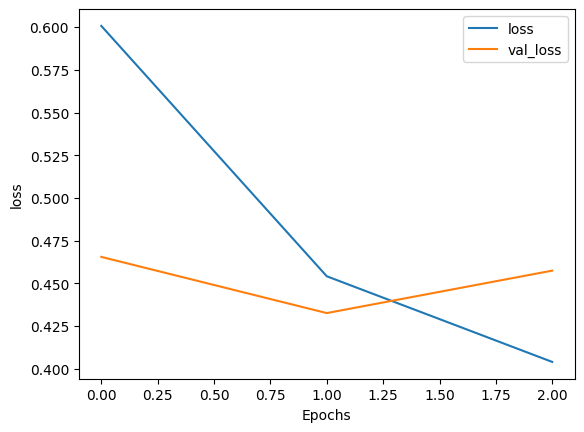

46/46 [==============================] - 4s 92ms/step - loss: 0.4326
y (true labels after decoding): [0, 1, 0, 0, 1] (type: <class 'list'>, length: 735)
yhats (predicted labels): [0, 1, 0, 0, 1] (type: <class 'list'>, length: 735)
### Start fold 2


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


184/184 [==============================] - 88s 349ms/step - loss: 0.5912 - val_loss: 0.4559
Epoch 2/5
184/184 [==============================] - 60s 328ms/step - loss: 0.4424 - val_loss: 0.3984
Epoch 3/5
184/184 [==============================] - 60s 326ms/step - loss: 0.4002 - val_loss: 0.4227


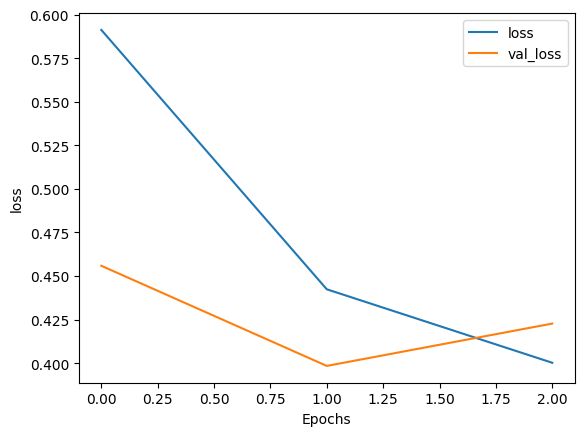

46/46 [==============================] - 4s 91ms/step - loss: 0.3984
y (true labels after decoding): [1, 0, 0, 0, 0] (type: <class 'list'>, length: 735)
yhats (predicted labels): [1, 0, 0, 0, 0] (type: <class 'list'>, length: 735)
### Start fold 3


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


184/184 [==============================] - 86s 349ms/step - loss: 0.5752 - val_loss: 0.5105
Epoch 2/5
184/184 [==============================] - 60s 329ms/step - loss: 0.4395 - val_loss: 0.4958
Epoch 3/5
184/184 [==============================] - 61s 331ms/step - loss: 0.3905 - val_loss: 0.4770
Epoch 4/5
184/184 [==============================] - 60s 327ms/step - loss: 0.3511 - val_loss: 0.5076


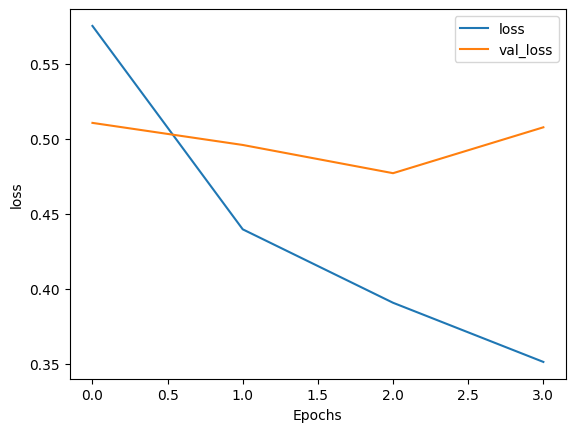

46/46 [==============================] - 4s 92ms/step - loss: 0.4770
y (true labels after decoding): [1, 1, 1, 1, 0] (type: <class 'list'>, length: 735)
yhats (predicted labels): [1, 1, 1, 1, 0] (type: <class 'list'>, length: 735)
### Start fold 4


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


184/184 [==============================] - 89s 352ms/step - loss: 0.5647 - val_loss: 0.5534
Epoch 2/5
184/184 [==============================] - 61s 330ms/step - loss: 0.4372 - val_loss: 0.5318
Epoch 3/5
184/184 [==============================] - 60s 328ms/step - loss: 0.3952 - val_loss: 0.5430


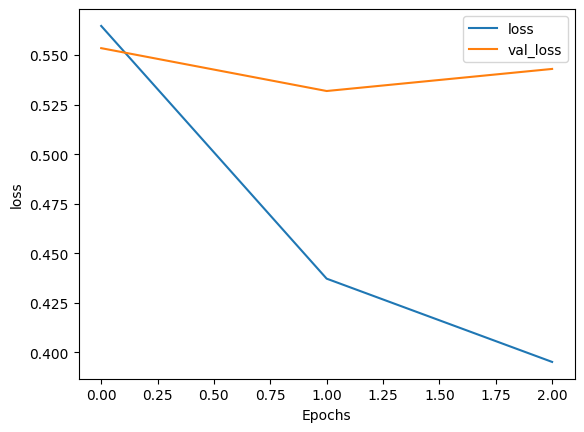

46/46 [==============================] - 4s 92ms/step - loss: 0.5318
y (true labels after decoding): [1, 1, 0, 0, 1] (type: <class 'list'>, length: 734)
yhats (predicted labels): [1, 1, 0, 0, 0] (type: <class 'list'>, length: 734)
### Start fold 5


/usr/local/lib/python3.10/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
All PyTorch model weights were used when initializing TFT5ForConditionalGeneration.

All the weights of TFT5ForConditionalGeneration were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFT5ForConditionalGeneration for predictions without further training.


Epoch 1/5


184/184 [==============================] - 89s 352ms/step - loss: 0.5784 - val_loss: 0.4795
Epoch 2/5
184/184 [==============================] - 61s 330ms/step - loss: 0.4471 - val_loss: 0.4449
Epoch 3/5
184/184 [==============================] - 60s 328ms/step - loss: 0.3967 - val_loss: 0.4813


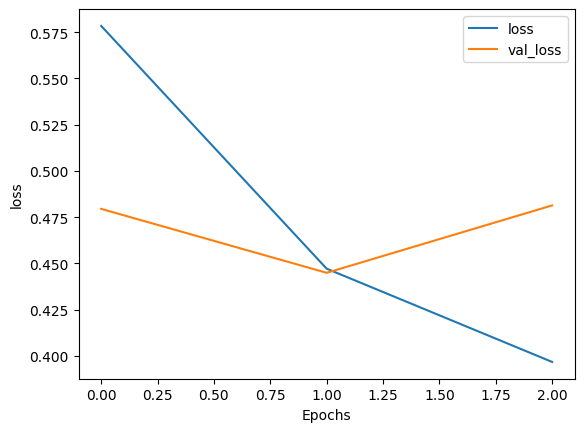

46/46 [==============================] - 4s 92ms/step - loss: 0.4449
y (true labels after decoding): [1, 1, 1, 0, 0] (type: <class 'list'>, length: 734)
yhats (predicted labels): [1, 1, 1, 0, 0] (type: <class 'list'>, length: 734)
5-Fold CV Loss: 0.4569428861141205
5-Fold CV Accuracy: 0.8042384474225658
5-Fold CV Precision: 0.8152390621753858
5-Fold CV Recall: 0.7845303867403315
5-Fold CV F1 Score: 0.7965738621220867
5-Fold CV Micro F1 Score: 0.8042384474225658
5-Fold CV Weighted Macro F1 Score: 0.8034199355248435
5 fold f1 per class [array([0.81182796, 0.80716253]), array([0.83989501, 0.82768362]), array([0.79494382, 0.80738786]), array([0.80048077, 0.73899371]), array([0.80325645, 0.80164159])]


In [17]:
tokenizer = T5Tokenizer.from_pretrained("google/flan-t5-base")
# without distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro, val_f1_per_class = run_model_5fold(df_sg2, model_name='t5',
                                                                                            freeze_encoder=False, pretrained=False, plot=True)

# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))
print("5 fold f1 per class", val_f1_per_class)

### BERT

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
# without distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='bert',
                                                                                            freeze_encoder=False, pretrained=False)

# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

0       1
1       0
3       1
4       0
5       1
       ..
1695    1
1696    0
1697    0
1698    1
1699    1
Name: Label_bias, Length: 1546, dtype: int64
### Start fold 1


KeyboardInterrupt: 

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
# without distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='bert',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for BERT on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for BERT on SG2
5-Fold CV Loss: 0.4575493991374969
5-Fold CV Accuracy: 0.7892706074255316
5-Fold CV Precision: 0.7796414062302606
5-Fold CV Recall: 0.8049723756906078
5-Fold CV F1 Score: 0.7900329021285127
5-Fold CV Micro F1 Score: 0.7892706074255315
5-Fold CV Weighted Macro F1 Score: 0.7886159511454031


### BERT + distant

In [ ]:
# load model layer weights from pretraining on distant dataset
# compile model
#transfer_model = TFRobertaForSequenceClassification.from_pretrained('roberta-base')
transfer_model = TFBertForSequenceClassification.from_pretrained('bert-base-uncased')
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
transfer_model.compile(optimizer=optimizer, loss=transfer_model.compute_loss)

transfer_model.load_weights('./checkpoints/bert_final_checkpoint_news_headlines_USA')
trained_model_layer = transfer_model.get_layer(index=0).get_weights()

All model checkpoint layers were used when initializing TFBertForSequenceClassification.

Some layers of TFBertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
# with distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='bert',
                                                                                            freeze_encoder=False, pretrained=True)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for BERT + distant on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for BERT + distant on SG1
5-Fold CV Loss: 0.4784796714782715
5-Fold CV Accuracy: 0.7791283150506451
5-Fold CV Precision: 0.782222153066104
5-Fold CV Recall: 0.7624161073825504
5-Fold CV F1 Score: 0.7690257043162897
5-Fold CV Micro F1 Score: 0.7791283150506451
5-Fold CV Weighted Macro F1 Score: 0.7782424758051683


In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
# with distant signal pretraining
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='bert',
                                                                                            freeze_encoder=False, pretrained=True)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for BERT + distant on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for BERT + distant on SG2
5-Fold CV Loss: 0.45280778408050537
5-Fold CV Accuracy: 0.8047893380785556
5-Fold CV Precision: 0.8010278449136129
5-Fold CV Recall: 0.8082872928176796
5-Fold CV F1 Score: 0.8027645188619399
5-Fold CV Micro F1 Score: 0.8047893380785558
5-Fold CV Weighted Macro F1 Score: 0.8043577261879854


### DistilBERT

In [ ]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='distilbert',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for DistilBERT on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for DistilBERT on SG1
5-Fold CV Loss: 0.5034848332405091
5-Fold CV Accuracy: 0.7603517841381919
5-Fold CV Precision: 0.7851353351520555
5-Fold CV Recall: 0.7006711409395974
5-Fold CV F1 Score: 0.736955546776338
5-Fold CV Micro F1 Score: 0.7603517841381919
5-Fold CV Weighted Macro F1 Score: 0.758224422060177


In [ ]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='distilbert',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for DistilBERT on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for DistilBERT on SG2
5-Fold CV Loss: 0.47459145188331603
5-Fold CV Accuracy: 0.7783788392741292
5-Fold CV Precision: 0.7914496007137517
5-Fold CV Recall: 0.756353591160221
5-Fold CV F1 Score: 0.768966991077014
5-Fold CV Micro F1 Score: 0.7783788392741293
5-Fold CV Weighted Macro F1 Score: 0.777102422253571


### RoBERTa

In [ ]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='roberta',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for RoBERTa on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for RoBERTa on SG1
5-Fold CV Loss: 0.4697426736354828
5-Fold CV Accuracy: 0.7784621527339974
5-Fold CV Precision: 0.7825771209819836
5-Fold CV Recall: 0.7758389261744967
5-Fold CV F1 Score: 0.7715627724463581
5-Fold CV Micro F1 Score: 0.7784621527339974
5-Fold CV Weighted Macro F1 Score: 0.7752193988259601


In [ ]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='roberta',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for RoBERTa on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for RoBERTa on SG2
5-Fold CV Loss: 0.45095362067222594
5-Fold CV Accuracy: 0.8007054811025227
5-Fold CV Precision: 0.7834945430249991
5-Fold CV Recall: 0.8337016574585636
5-Fold CV F1 Score: 0.8042913565026074
5-Fold CV Micro F1 Score: 0.8007054811025227
5-Fold CV Weighted Macro F1 Score: 0.799347878132545


### RoBERTa + distant

In [ ]:
# load model layer weights from pretraining on distant dataset
# compile model
transfer_model = TFRobertaForSequenceClassification.from_pretrained('roberta-base')
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-5)
transfer_model.compile(optimizer=optimizer, loss=transfer_model.compute_loss)

transfer_model.load_weights('./checkpoints/roberta_final_checkpoint_news_headlines_USA')
trained_model_layer = transfer_model.get_layer(index=0).get_weights()

All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='roberta',
                                                                                            freeze_encoder=False, pretrained=True)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for RoBERTa + distant on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for RoBERTa + distant on SG1
5-Fold CV Loss: 0.44771517515182496
5-Fold CV Accuracy: 0.7985668053629219
5-Fold CV Precision: 0.7758359785184737
5-Fold CV Recall: 0.832214765100671
5-Fold CV F1 Score: 0.7999256262460596
5-Fold CV Micro F1 Score: 0.7985668053629217
5-Fold CV Weighted Macro F1 Score: 0.7977665899984501


In [ ]:
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='roberta',
                                                                                            freeze_encoder=False, pretrained=True)

### Start fold 1


All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 97s 877ms/step - loss: 0.5345 - val_loss: 0.4133
Epoch 2/10
23/23 [==============================] - 5s 234ms/step - loss: 0.4133
### Start fold 2


All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 95s 874ms/step - loss: 0.5673 - val_loss: 0.4084
Epoch 2/10
92/92 [==============================] - 77s 841ms/step - loss: 0.3456 - val_loss: 0.4032
Epoch 3/10
23/23 [==============================] - 5s 215ms/step - loss: 0.4032
### Start fold 3


...

Epoch 1/10
92/92 [==============================] - 96s 875ms/step - loss: 0.5386 - val_loss: 0.4585
Epoch 2/10
23/23 [==============================] - 5s 222ms/step - loss: 0.4585
### Start fold 4


All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 97s 882ms/step - loss: 0.5422 - val_loss: 0.4699
Epoch 2/10
92/92 [==============================] - 78s 845ms/step - loss: 0.3178 - val_loss: 0.4695
Epoch 3/10
23/23 [==============================] - 5s 233ms/step - loss: 0.4695
### Start fold 5


All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 89s 800ms/step - loss: 0.5482 - val_loss: 0.4198
Epoch 2/10
23/23 [==============================] - 6s 263ms/step - loss: 0.4198


In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for RoBERTa + distant on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for RoBERTa + distant on SG2
5-Fold CV Loss: 0.4328740358352661
5-Fold CV Accuracy: 0.8007017738975699
5-Fold CV Precision: 0.8479610779798031
5-Fold CV Recall: 0.72707182320442
5-Fold CV F1 Score: 0.7811997062364262
5-Fold CV Micro F1 Score: 0.8007017738975699
5-Fold CV Weighted Macro F1 Score: 0.7990983671260622


### ELECTRA

In [ ]:
tokenizer = ElectraTokenizer.from_pretrained('google/electra-small-discriminator')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='electra',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for ELECTRA on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for ELECTRA on SG1
5-Fold CV Loss: 0.5440825581550598
5-Fold CV Accuracy: 0.7448009918883706
5-Fold CV Precision: 0.7614052309887166
5-Fold CV Recall: 0.6966442953020134
5-Fold CV F1 Score: 0.7211321040106528
5-Fold CV Micro F1 Score: 0.7448009918883706
5-Fold CV Weighted Macro F1 Score: 0.7422210680339413


In [ ]:
tokenizer = ElectraTokenizer.from_pretrained('google/electra-small-discriminator')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='electra',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for ELECTRA on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for ELECTRA on SG2
5-Fold CV Loss: 0.5140148580074311
5-Fold CV Accuracy: 0.7625935605849968
5-Fold CV Precision: 0.809470758694404
5-Fold CV Recall: 0.6861878453038674
5-Fold CV F1 Score: 0.7379172614803242
5-Fold CV Micro F1 Score: 0.7625935605849969
5-Fold CV Weighted Macro F1 Score: 0.7597981280791523


### XLNET

In [ ]:
tokenizer = XLNetTokenizer.from_pretrained('xlnet-base-cased')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg1, model_name='xlnet',
                                                                                            freeze_encoder=False, pretrained=False)

In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for XLNET on SG1')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for XLNET on SG1
5-Fold CV Loss: 0.5028677642345428
5-Fold CV Accuracy: 0.7616525868953054
5-Fold CV Precision: 0.7908365542157949
5-Fold CV Recall: 0.6939597315436242
5-Fold CV F1 Score: 0.7374808169992624
5-Fold CV Micro F1 Score: 0.7616525868953054
5-Fold CV Weighted Macro F1 Score: 0.7600315195814671


In [ ]:
tokenizer = XLNetTokenizer.from_pretrained('xlnet-base-cased')
val_loss, val_acc, val_prec, val_rec, val_f1, val_f1_micro, val_f1_wmacro = run_model_5fold(df_sg2, model_name='xlnet',
                                                                                            freeze_encoder=False, pretrained=False)

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


### Start fold 1


Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFXLNetForSequenceClassification were not initialized from the model checkpoint at xlnet-base-cased and are newly initialized: ['sequence_summary', 'logits_proj']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 120s 1s/step - loss: 0.5646 - val_loss: 0.4400
Epoch 2/10
23/23 [==============================] - 6s 274ms/step - loss: 0.4400
### Start fold 2


Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFXLNetForSequenceClassification were not initialized from the model checkpoint at xlnet-base-cased and are newly initialized: ['sequence_summary', 'logits_proj']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

Epoch 1/10
92/92 [==============================] - 120s 1s/step - loss: 0.6138 - val_loss: 0.4555
Epoch 2/10
92/92 [==============================] - 102s 1s/step - loss: 0.4001 - val_loss: 0.4433
Epoch 3/10
23/23 [==============================] - 6s 283ms/step - loss: 0.4433
### Start fold 4


Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFXLNetForSequenceClassification were not initialized from the model checkpoint at xlnet-base-cased and are newly initialized: ['sequence_summary', 'logits_proj']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 121s 1s/step - loss: 0.5813 - val_loss: 0.4738
Epoch 2/10
23/23 [==============================] - 7s 324ms/step - loss: 0.4738
### Start fold 5


Some layers from the model checkpoint at xlnet-base-cased were not used when initializing TFXLNetForSequenceClassification: ['lm_loss']
- This IS expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFXLNetForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some layers of TFXLNetForSequenceClassification were not initialized from the model checkpoint at xlnet-base-cased and are newly initialized: ['sequence_summary', 'logits_proj']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/10
92/92 [==============================] - 113s 1s/step - loss: 0.5735 - val_loss: 0.4463
Epoch 2/10
23/23 [==============================] - 8s 350ms/step - loss: 0.4463


In [ ]:
# inspect metrics
loss_cv = np.mean(val_loss)
acc_cv = np.mean(val_acc)
prec_cv = np.mean(val_prec)
rec_cv = np.mean(val_rec)
f1_cv = np.mean(val_f1)
f1_micro_cv = np.mean(val_f1_micro)
f1_wmacro_cv = np.mean(val_f1_wmacro)

print('Results for XLNET on SG2')
print('5-Fold CV Loss: {}'.format(loss_cv))
print('5-Fold CV Accuracy: {}'.format(acc_cv))
print('5-Fold CV Precision: {}'.format(prec_cv))
print('5-Fold CV Recall: {}'.format(rec_cv))
print('5-Fold CV F1 Score: {}'.format(f1_cv))
print('5-Fold CV Micro F1 Score: {}'.format(f1_micro_cv))
print('5-Fold CV Weighted Macro F1 Score: {}'.format(f1_wmacro_cv))

Results for XLNET on SG2
5-Fold CV Loss: 0.4420862317085266
5-Fold CV Accuracy: 0.7974357263341304
5-Fold CV Precision: 0.8162492174406484
5-Fold CV Recall: 0.76353591160221
5-Fold CV F1 Score: 0.7870615420108473
5-Fold CV Micro F1 Score: 0.7974357263341304
5-Fold CV Weighted Macro F1 Score: 0.7967053530729449
